# Parametric State Estimation with Shallow Decoder Network on TRIGA-MC data
This notebook implements a Shallow Decoder Network (SDN) to reconstruct the state (the total flux $\Phi$) of a TRIGA reactor based on its operational parameters (position of the SHIM and REG control rod) and few local measurements.
In particular, let $\mathbf{f}$ be the SDN model, $\mathbf{y}$ the input measures, $\boldsymbol{\mu}$ the parameters and $\mathbf{u}$ the output state of the reactor, such that:
$$\mathbf{u} = \mathbf{f}(\mathbf{y}, \boldsymbol{\mu})$$

This notebook can load MonteCarlo data either with low or high statistics (the uncertainty is higher for low statistics, two times higher).

In [ ]:
# from matplotlib import rcParams
# rcParams.update({
#   "text.usetex": True,
#   "font.family": "serif"
# })

# rcParams['text.latex.preamble'] = r'\usepackage{amssymb} \usepackage{amsmath} \usepackage{amsthm} \usepackage{mathtools}'

import os
path_res = os.path.join(os.getcwd(), 'Results/ReconstructionFromSparseSensors/')
os.makedirs(path_res, exist_ok=True)

Let us import the data

In [9]:
# _stats = '_lowstats400'
_stats = '_highstats'

import numpy as np
_tmp = np.load(f'Data/flux_data{_stats}.npz', allow_pickle=True)

snaps = _tmp['flux']
params = _tmp['params']
centroids = _tmp['centroids']

del _tmp

Let us separate the data into a training and test set, the seed is set to 42 for reproducibility.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(params)), params, test_size=0.2, random_state=42)

valid_indices = test_indices[::2]
test_indices = test_indices[1::2]

valid_params = test_params[::2]
test_params = test_params[1::2]

max_flux = snaps[:, train_indices].max()
train_data = snaps[:, train_indices] / max_flux
test_data  = snaps[:, test_indices] / max_flux
valid_data = snaps[:, valid_indices] / max_flux

print(train_data.shape, test_data.shape, valid_data.shape)

(126750, 96) (126750, 12) (126750, 13)


Let us plot the parameters

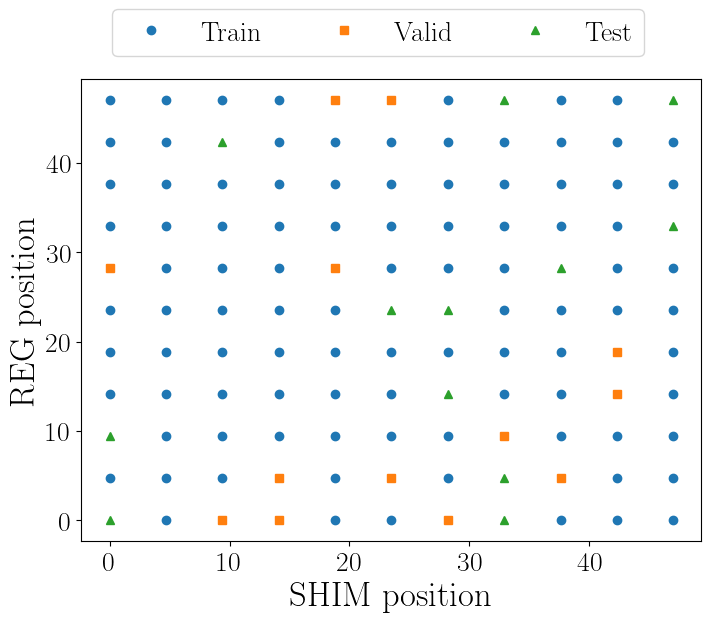

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(*train_params.T, 'o', label='Train')
plt.plot(*valid_params.T, 's', label='Valid')
plt.plot(*test_params.T, '^', label='Test')

plt.legend(ncols=3, loc=(0.05, 1.05), fontsize=20)
plt.xlabel('SHIM position', fontsize=25)
plt.ylabel('REG  position', fontsize=25)

plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

fig = plt.gcf()
fig.savefig(os.path.join(path_res, 'param_distribution.pdf'), dpi=300, bbox_inches ='tight')

## Singular Value Decomposition (SVD)

Instead of working with the high-dimensional flux data (with dimension $\mathcal{N}_h$\sim 10^5$), we can use the Singular Value Decomposition (SVD) to reduce the dimensionality of the data and hence the state vector $\mathbf{u}$ is replaced by a low-dimensional representation $\mathbf{v} = \mathbb{U}\mathbf{u}$ being $\mathbb{U}$ the SVD modes.

Let us perform the SVD on the snaps matrix

In [15]:
from sklearn.decomposition import randomized_svd

modes, sing_vals, _ = randomized_svd(train_data, n_components=30, n_iter='auto')

Let us plot the singular values

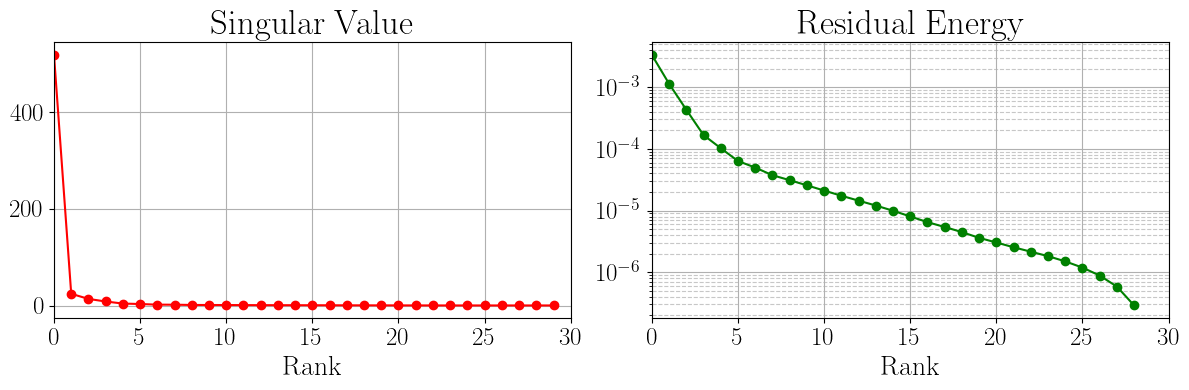

In [16]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1,2, figsize=(12, 4))

axs[0].plot(sing_vals, marker='o', color='r')
axs[1].semilogy(1-np.cumsum(sing_vals[:-1]**2)/np.sum(sing_vals**2), marker='o', color='g')

for ax in axs:
    ax.set_xlabel('Rank', fontsize=20)
    ax.tick_params(axis='both', which='major', labelsize=18)
    ax.grid(True, which='major', linestyle='-', alpha=1)
    ax.grid(True, which='minor', linestyle='--', alpha=0.7)
    ax.set_xlim(0, len(sing_vals))

axs[0].set_title('Singular Value', fontsize=25)
axs[1].set_title('Residual Energy', fontsize=25)

plt.tight_layout()

fig.savefig(os.path.join(path_res, 'svd_analysis.pdf'), dpi=300, bbox_inches ='tight')

Let us see the project the snapshots on the SVD modes and compute the error on the test set

In [17]:
rank = 5
train_pod_coeffs = np.dot(modes[:,:rank].T, train_data)
test_pod_coeffs  = np.dot(modes[:,:rank].T, test_data)
valid_pod_coeffs = np.dot(modes[:,:rank].T, valid_data)

## Extract Measurements

Let us get some measurements from the flux data

In [18]:
xmin, xmax = -20, 20
ymin, ymax = -20, 20
zmin, zmax = 20.0, 50.0

mask = (
    (centroids[:, 0] >= xmin) & (centroids[:, 0] <= xmax) &
    (centroids[:, 1] >= ymin) & (centroids[:, 1] <= ymax) &
    (centroids[:, 2] >= zmin) & (centroids[:, 2] <= zmax)
)

cell_indices = np.where(mask)[0] 
non_cell_indices = np.setdiff1d(np.arange(centroids.shape[0]), cell_indices)

np.random.seed(60)
n_sensors = 3
idx_sens_locs = np.random.choice(cell_indices, size=n_sensors)

train_measures = np.concatenate([train_data[idx_sens_locs], params[train_indices].T], axis=0)
test_measures  = np.concatenate([test_data[idx_sens_locs],  params[test_indices].T], axis=0)
valid_measures = np.concatenate([valid_data[idx_sens_locs], params[valid_indices].T], axis=0)

input_scaler = MinMaxScaler()
input_scaler.fit(train_measures.T)

train_measures = input_scaler.transform(train_measures.T).T
test_measures  = input_scaler.transform(test_measures.T).T
valid_measures = input_scaler.transform(valid_measures.T).T

## Shallow Decoding Network training
The SDN exploits the low-dimensional representation of the state vector $\mathbf{v}$, which is obtained by projecting the high-dimensional flux data on the SVD modes. The predicted state vector $\hat{\mathbf{u}}$ is defined as:
$$\hat{\mathbf{u}} = \mathbb{U}\hat{\mathbf{v}} = \mathbb{U}\mathbf{f}(\mathbf{y}, \boldsymbol{\mu})$$
where $\hat{\mathbf{v}}$ is the output of the SDN.

If the flag variable `compressive_training` is set to `True`, the SDN is trained with the low-dimensional representation of the state vector $\mathbf{v}$, otherwise it is trained with the high-dimensional flux data $\mathbf{u}$.

Both cases will be fitted and compared

In [21]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

def train(compressive_training = True):

    train_dataset = MyDataset(torch.tensor(train_measures.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_measures.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_measures.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    train_error_list = []
    valid_error_list = []

    in_dim = train_measures.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    train_error_list, valid_error_list = fit(
        model=sdn,
        train_dataset=train_dataset,
        valid_dataset=valid_dataset,
        batch_size=32,
        epochs=500,
        optim=torch.optim.Adam,
        criterion=torch.nn.MSELoss(),
        lr=0.001,
        verbose=True,
        patience=30
    )

    return sdn, train_error_list, valid_error_list, test_dataset

import time

print("Compressive Training")
compr_time = time.time()
sdn_compr, train_error_list_compr, valid_error_list_compr, test_dataset_compr = train(compressive_training=True)
compr_time = time.time() - compr_time

print("Full Training")
full_time = time.time()
sdn_full, train_error_list_full, valid_error_list_full, test_dataset_full = train(compressive_training=False)
full_time = time.time() - full_time

Compressive Training
Training done: Training MRE = 2.50% 	 Validation MRE = 2.55%       
Full Training


/Users/sriva/Github/SDN4Neutronics/utils/sdn.py:10: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  num2p = lambda prob : ("%.2f" % (100*prob)) + "%"


Training done: Training MRE = 2.47% 	 Validation MRE = 2.65%       


Let us plot the training and validation losses

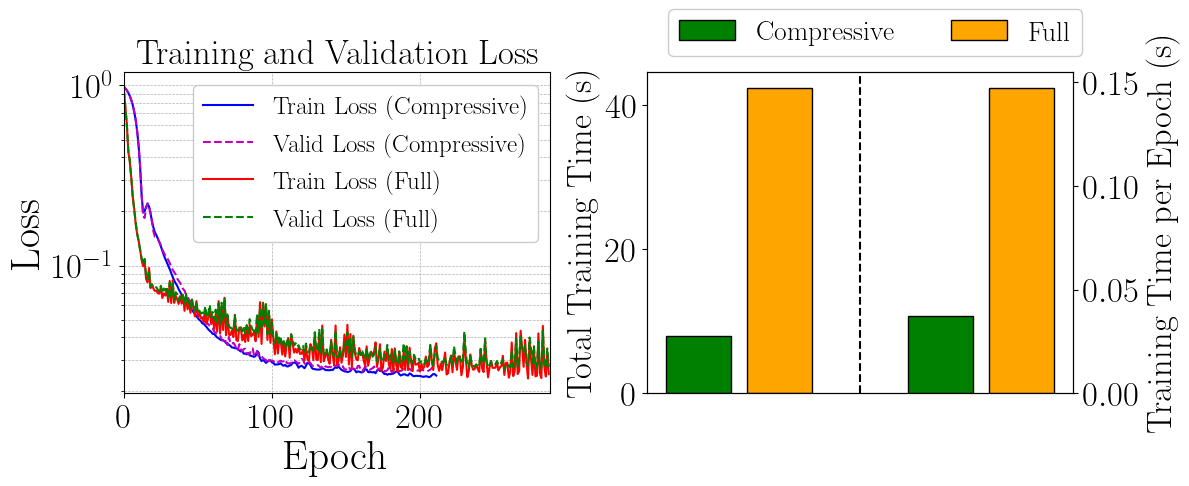

In [30]:
from matplotlib.patches import Patch

train_error_list = [[float(x) for x in train_error_list_compr],
                    [float(x) for x in train_error_list_full]]
valid_error_list = [[float(x) for x in valid_error_list_compr],
                    [float(x) for x in valid_error_list_full]]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))  # 2 subplots: training + time

# --- Training Loss (merged) ---
axs[0].semilogy(train_error_list[0], 'b',   label='Train Loss (Compressive)')
axs[0].plot(valid_error_list[0], 'm--', label='Valid Loss (Compressive)')
axs[0].plot(train_error_list[1], 'r',   label='Train Loss (Full)')
axs[0].plot(valid_error_list[1], 'g--', label='Valid Loss (Full)')

axs[0].set_xlabel('Epoch', fontsize=30)
axs[0].set_ylabel('Loss', fontsize=30)
axs[0].set_xlim(0, max(len(train_error_list[0]), len(train_error_list[1])))
# axs[0].set_ylim(1e-6, max(max(train_error_list[0]), max(train_error_list[1])) * 1.1)
axs[0].grid(True, which="both", ls="--", linewidth=0.5)
axs[0].tick_params(axis='both', which='major', labelsize=25)
axs[0].legend(framealpha=1, fontsize=18)
axs[0].set_title('Training and Validation Loss', fontsize=25)

# --- Training Time ---
axs[1].bar([1,2], [compr_time, full_time], color=['green', 'orange'], edgecolor='black', label='Total Time')
axs[1].axvline(3, color='black', linestyle='--')
axs[1].tick_params(axis='both', which='major', labelsize=25)
axs[1].set_ylabel('Total Training Time (s)', fontsize=25)
axs[1].set_xticks([])

_ax = axs[1].twinx()
_ax.bar([4,5], [compr_time/len(train_error_list[0]), full_time/len(train_error_list[1])],
        color=['green', 'orange'], edgecolor='black', label='Time per Epoch')
_ax.tick_params(axis='both', which='major', labelsize=25)
_ax.set_ylabel('Training Time per Epoch (s)', fontsize=25)

# Legend for compressive vs full
legend_elements = [Patch(facecolor='green', edgecolor='black', label='Compressive'),
                   Patch(facecolor='orange', edgecolor='black', label='Full')]
axs[1].legend(handles=legend_elements, fontsize=20, framealpha=1, loc=(0.05, 1.05), ncol=2)

plt.tight_layout()
fig.savefig(os.path.join(path_res, 'training_loss_and_time.pdf'), dpi=300, bbox_inches='tight')
plt.show()


Let us compare the predicted state with the true state for both the compressive and non-compressive training

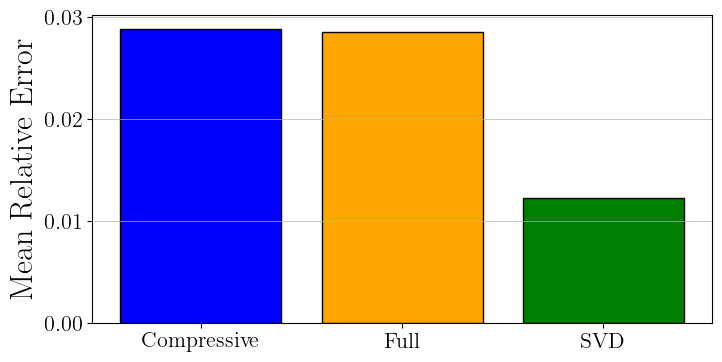

In [23]:
pred_sdn_compr = sdn_compr(test_dataset_compr.X).cpu().detach().numpy().T
pred_sdn_full = sdn_full(test_dataset_full.X).cpu().detach().numpy().T
pred_svd_full = np.dot(modes[:, :rank], test_pod_coeffs)

test_fom = test_dataset_compr.Y.cpu().detach().numpy().T

l2_err_compr = (np.linalg.norm(pred_sdn_compr - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)).mean()
l2_err_full = (np.linalg.norm(pred_sdn_full - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)).mean()
l2_err_svd = (np.linalg.norm(pred_svd_full - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)).mean()

fig, axs = plt.subplots(1, 1, figsize=(8, 4))
axs.bar(['Compressive', 'Full', 'SVD'], [l2_err_compr, l2_err_full, l2_err_svd], color=['blue', 'orange', 'green'], edgecolor='black')
axs.set_ylabel('Mean Relative Error', fontsize=23)
axs.tick_params(axis='both', which='major', labelsize=16)
axs.grid(axis='y', which="both", ls="-", linewidth=0.5)

fig.savefig(os.path.join(path_res, 'test_error_comparison.pdf'), dpi=300, bbox_inches ='tight')

Let us compute the error on each element of the test set

<BarContainer object of 12 artists>

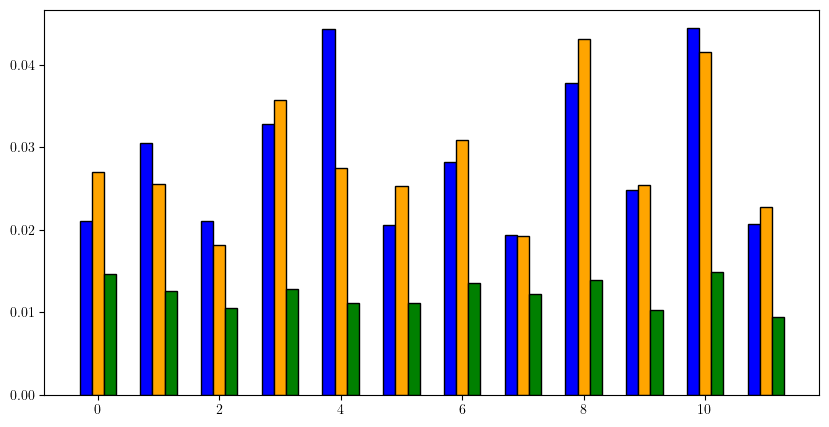

In [27]:
l2_err_compr = np.linalg.norm(pred_sdn_compr - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)
l2_err_full  = np.linalg.norm(pred_sdn_full - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)
l2_err_svd   = np.linalg.norm(pred_svd_full - test_fom, axis=0) / np.linalg.norm(test_fom, axis=0)

fig, axs = plt.subplots(1, 1, figsize=(10, 5))

axs.bar(np.arange(len(l2_err_compr))-0.2, l2_err_compr, width=0.2, label='Compressive', color='blue', edgecolor='black')
axs.bar(np.arange(len(l2_err_full)),      l2_err_full,  width=0.2, label='Full',        color='orange', edgecolor='black')
axs.bar(np.arange(len(l2_err_svd))+0.2,   l2_err_svd,   width=0.2, label='SVD',         color='green', edgecolor='black')

Let us make some plots for test parameters

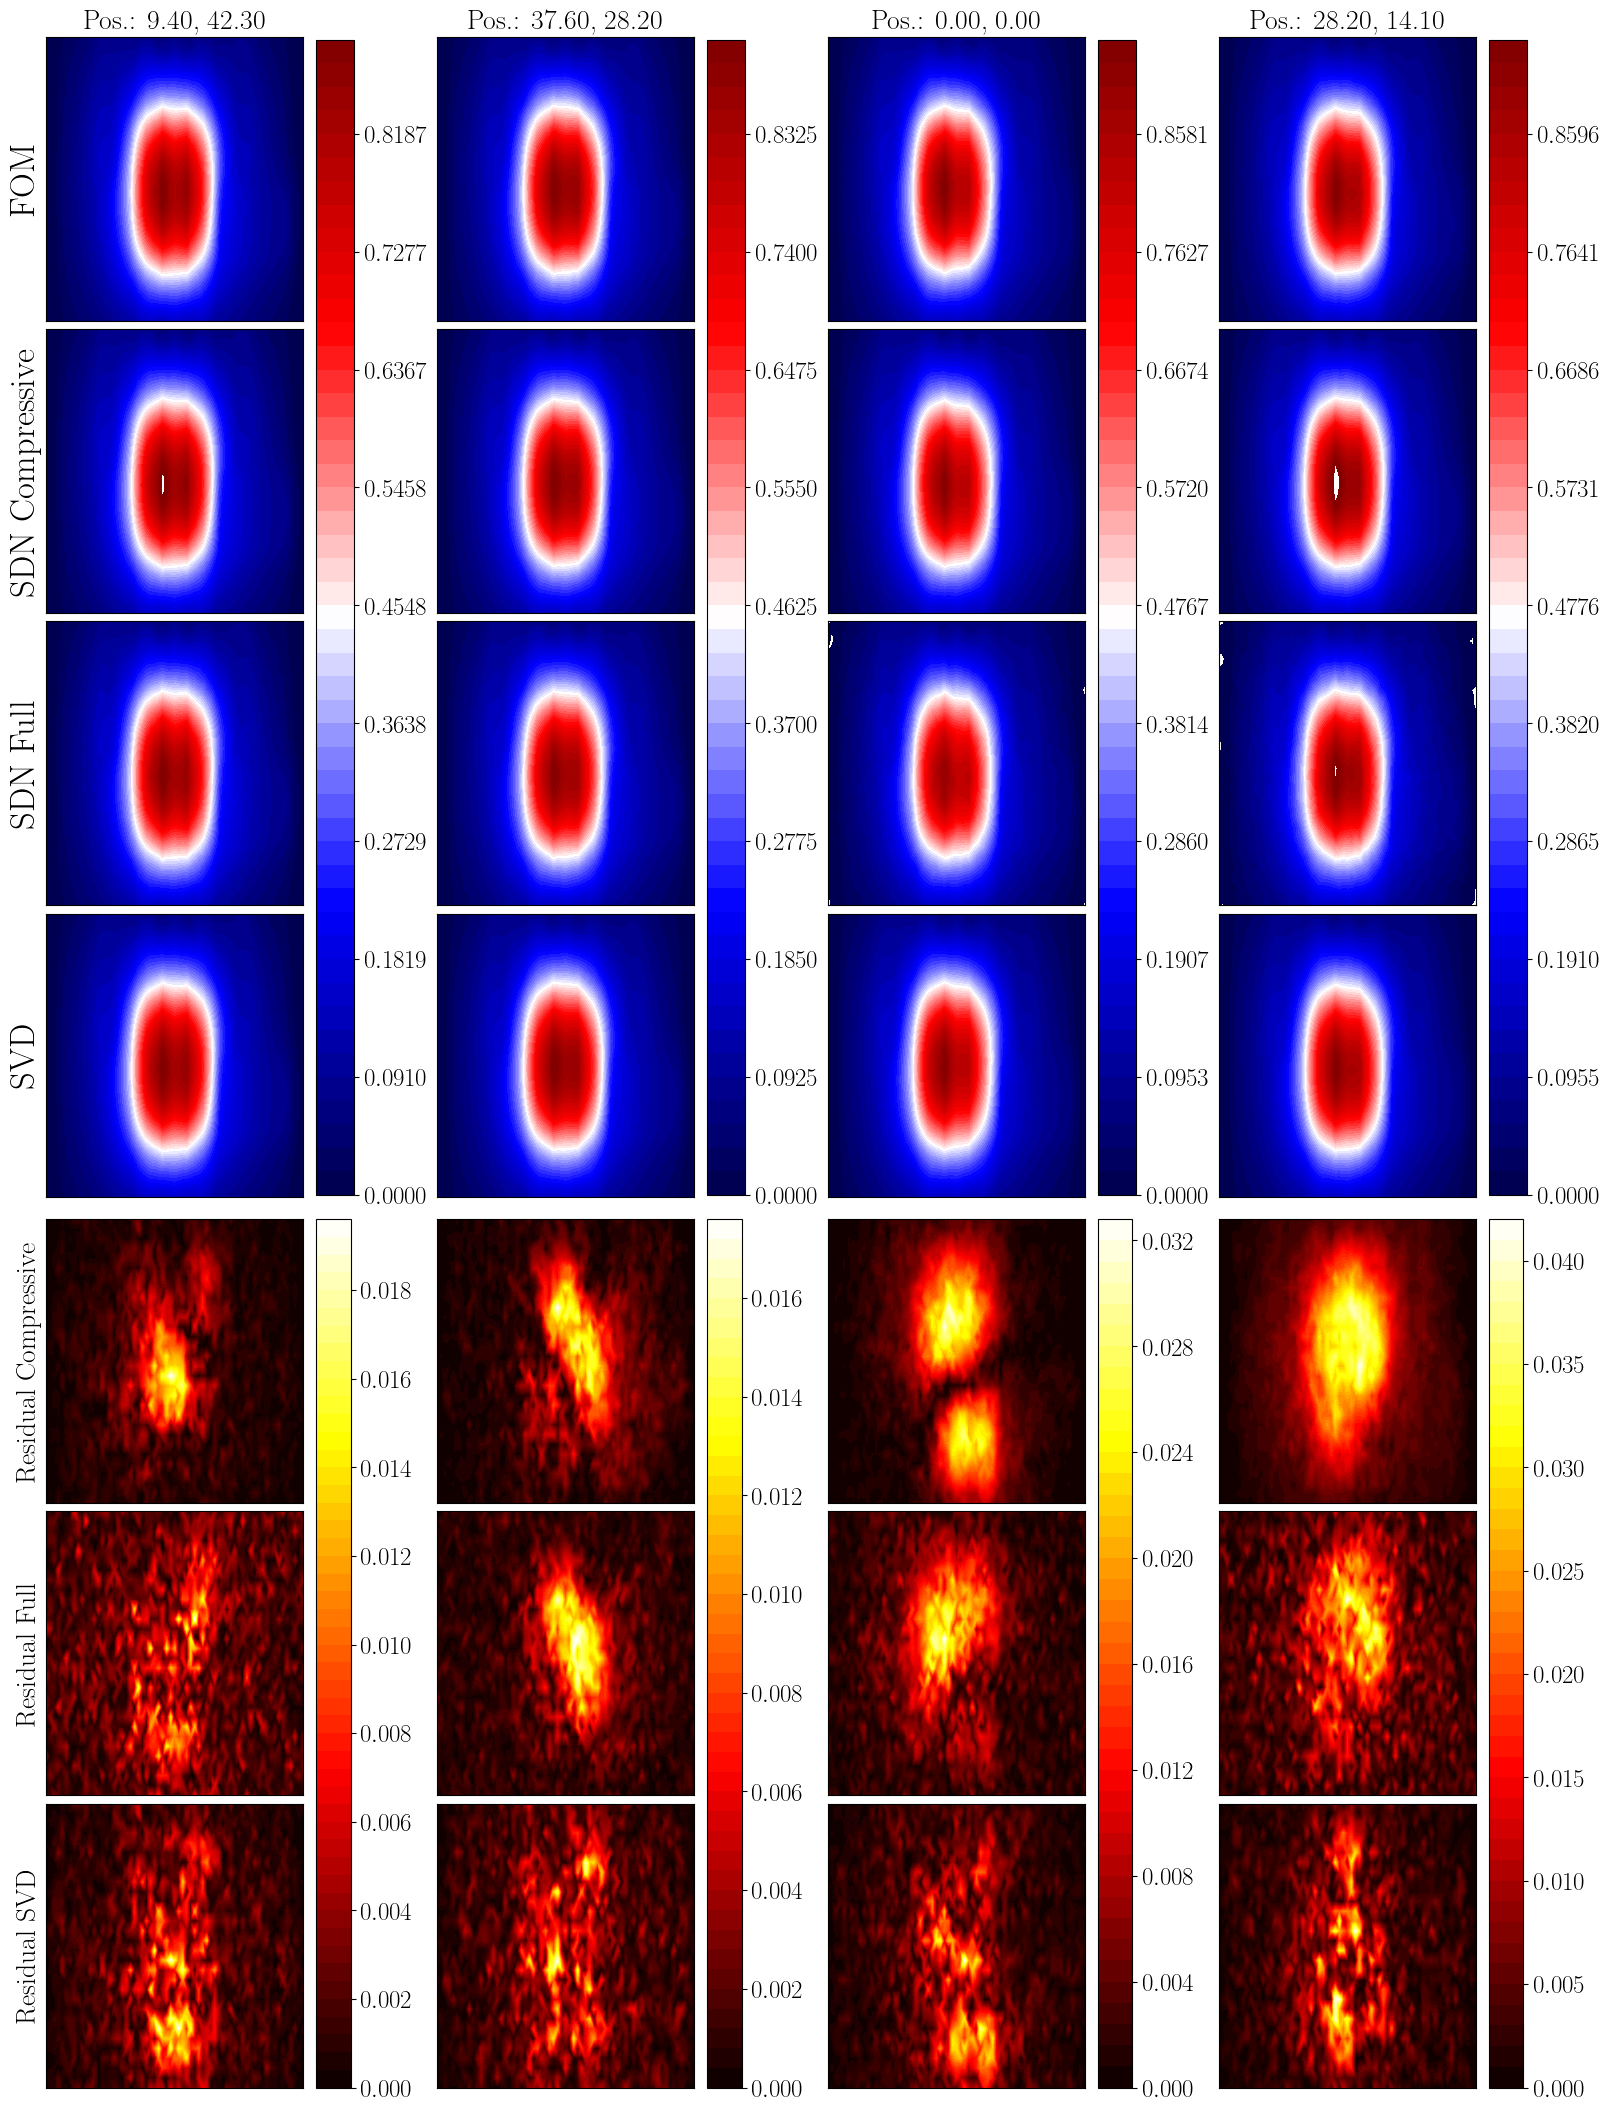

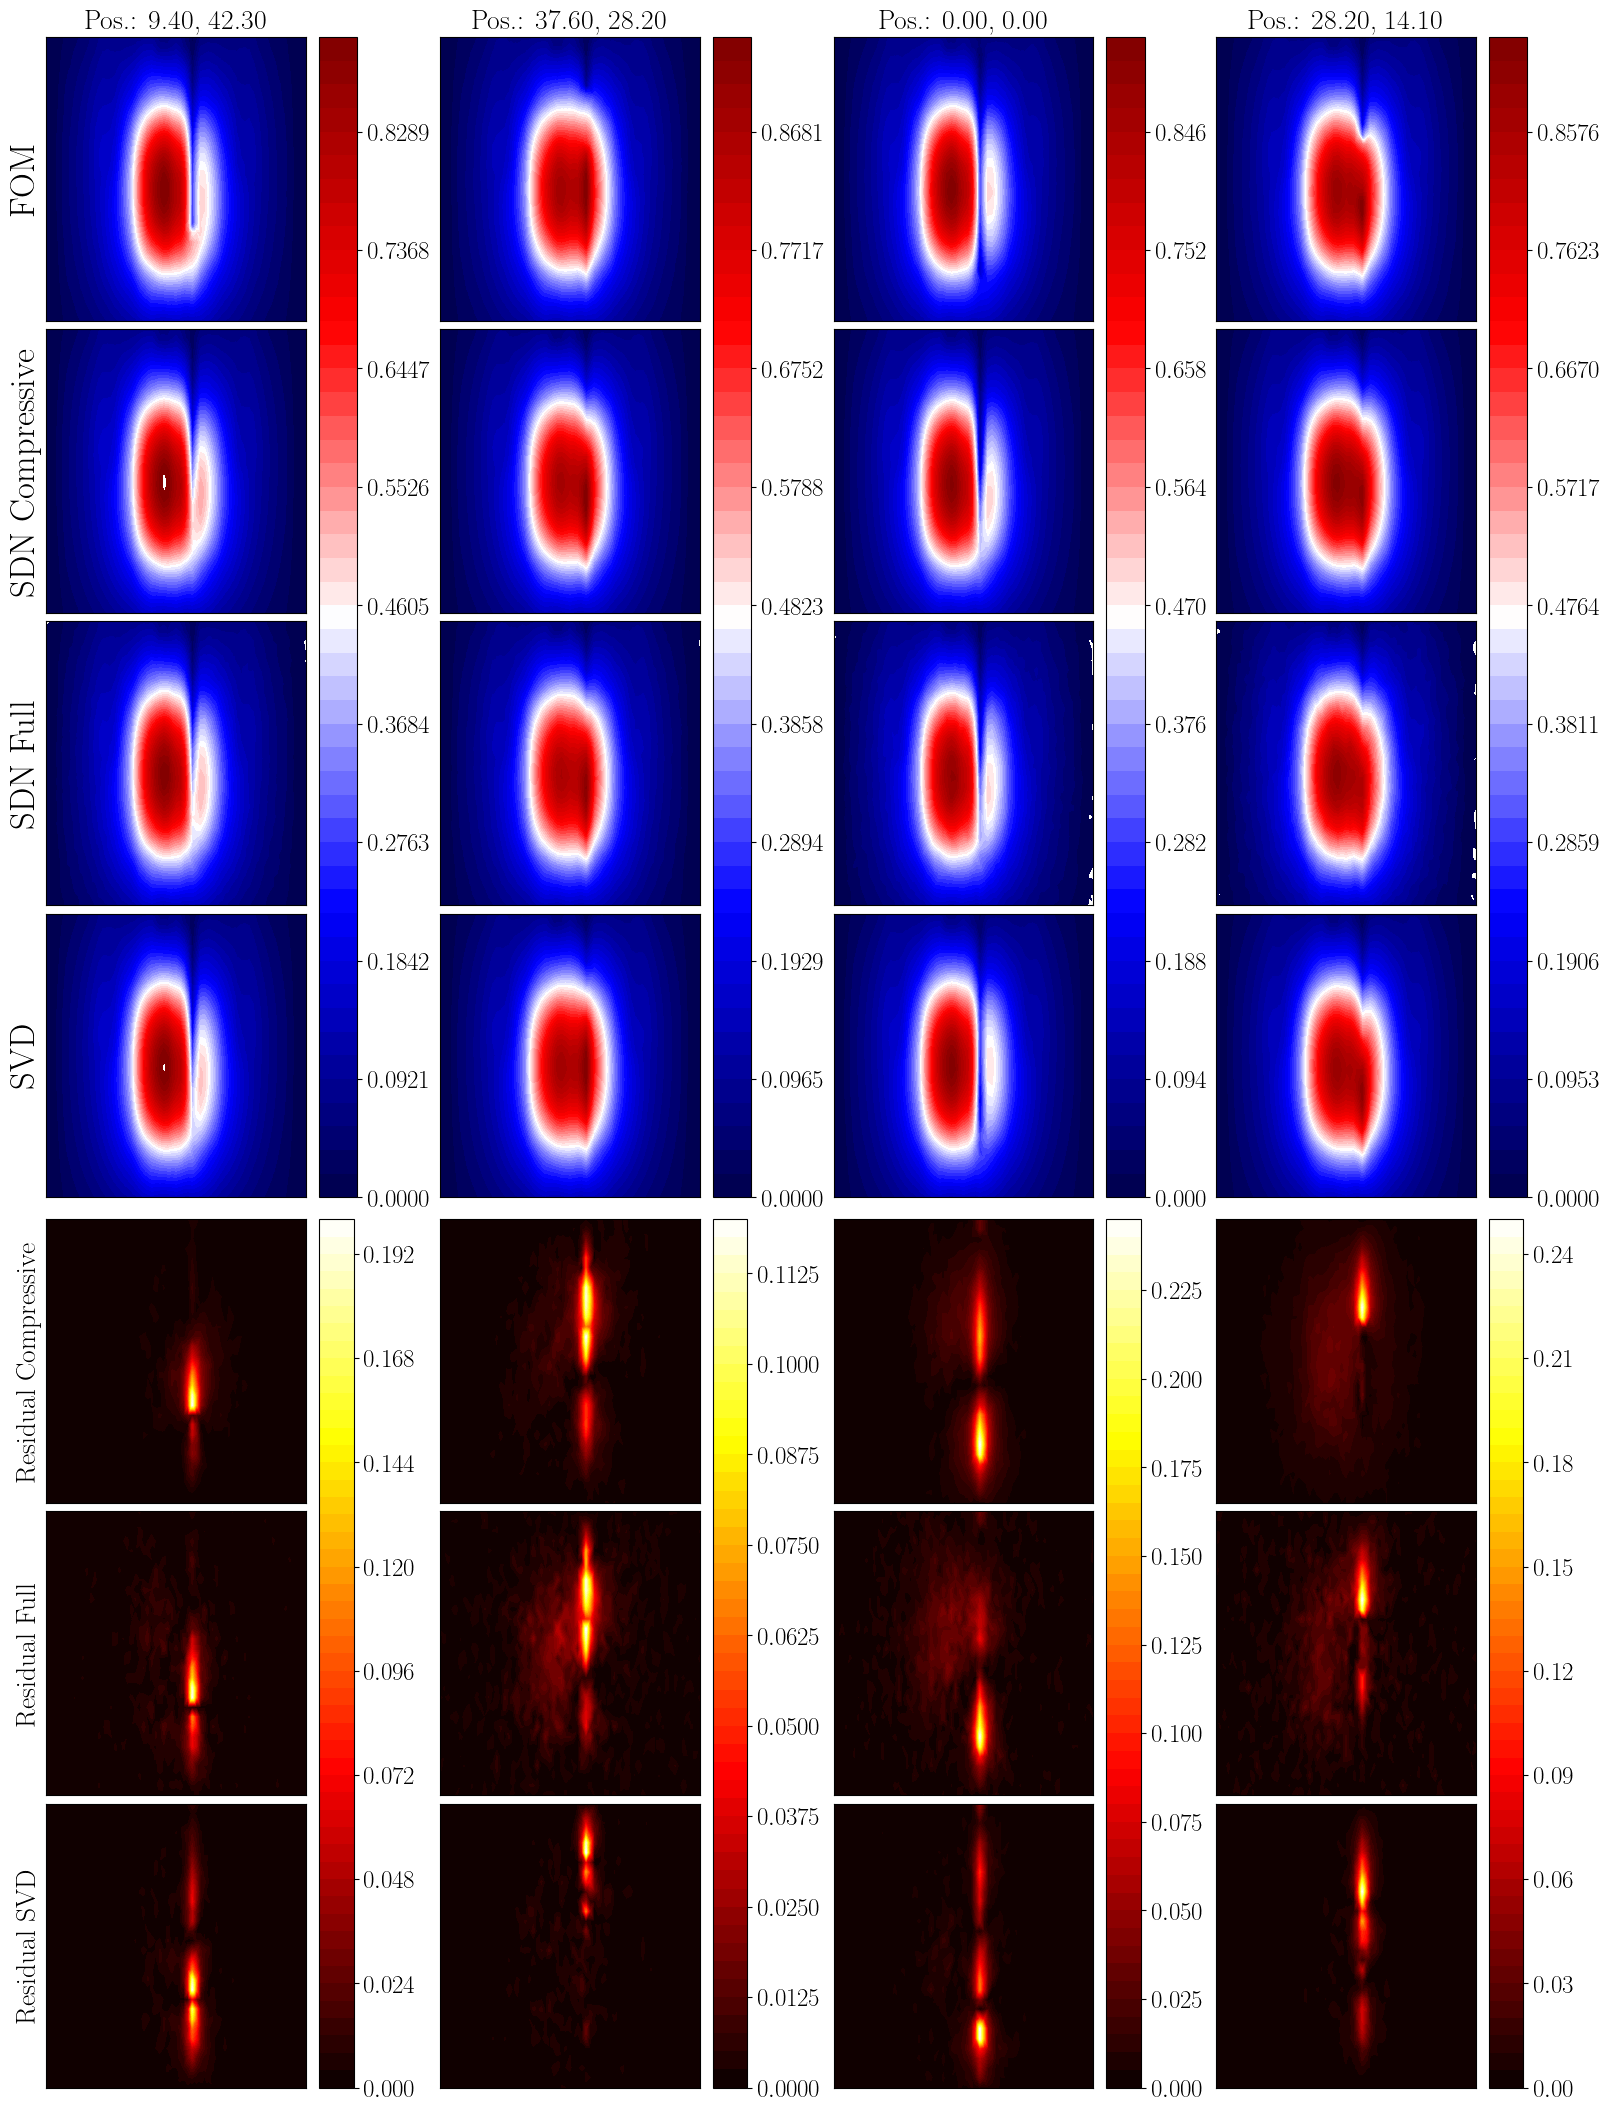

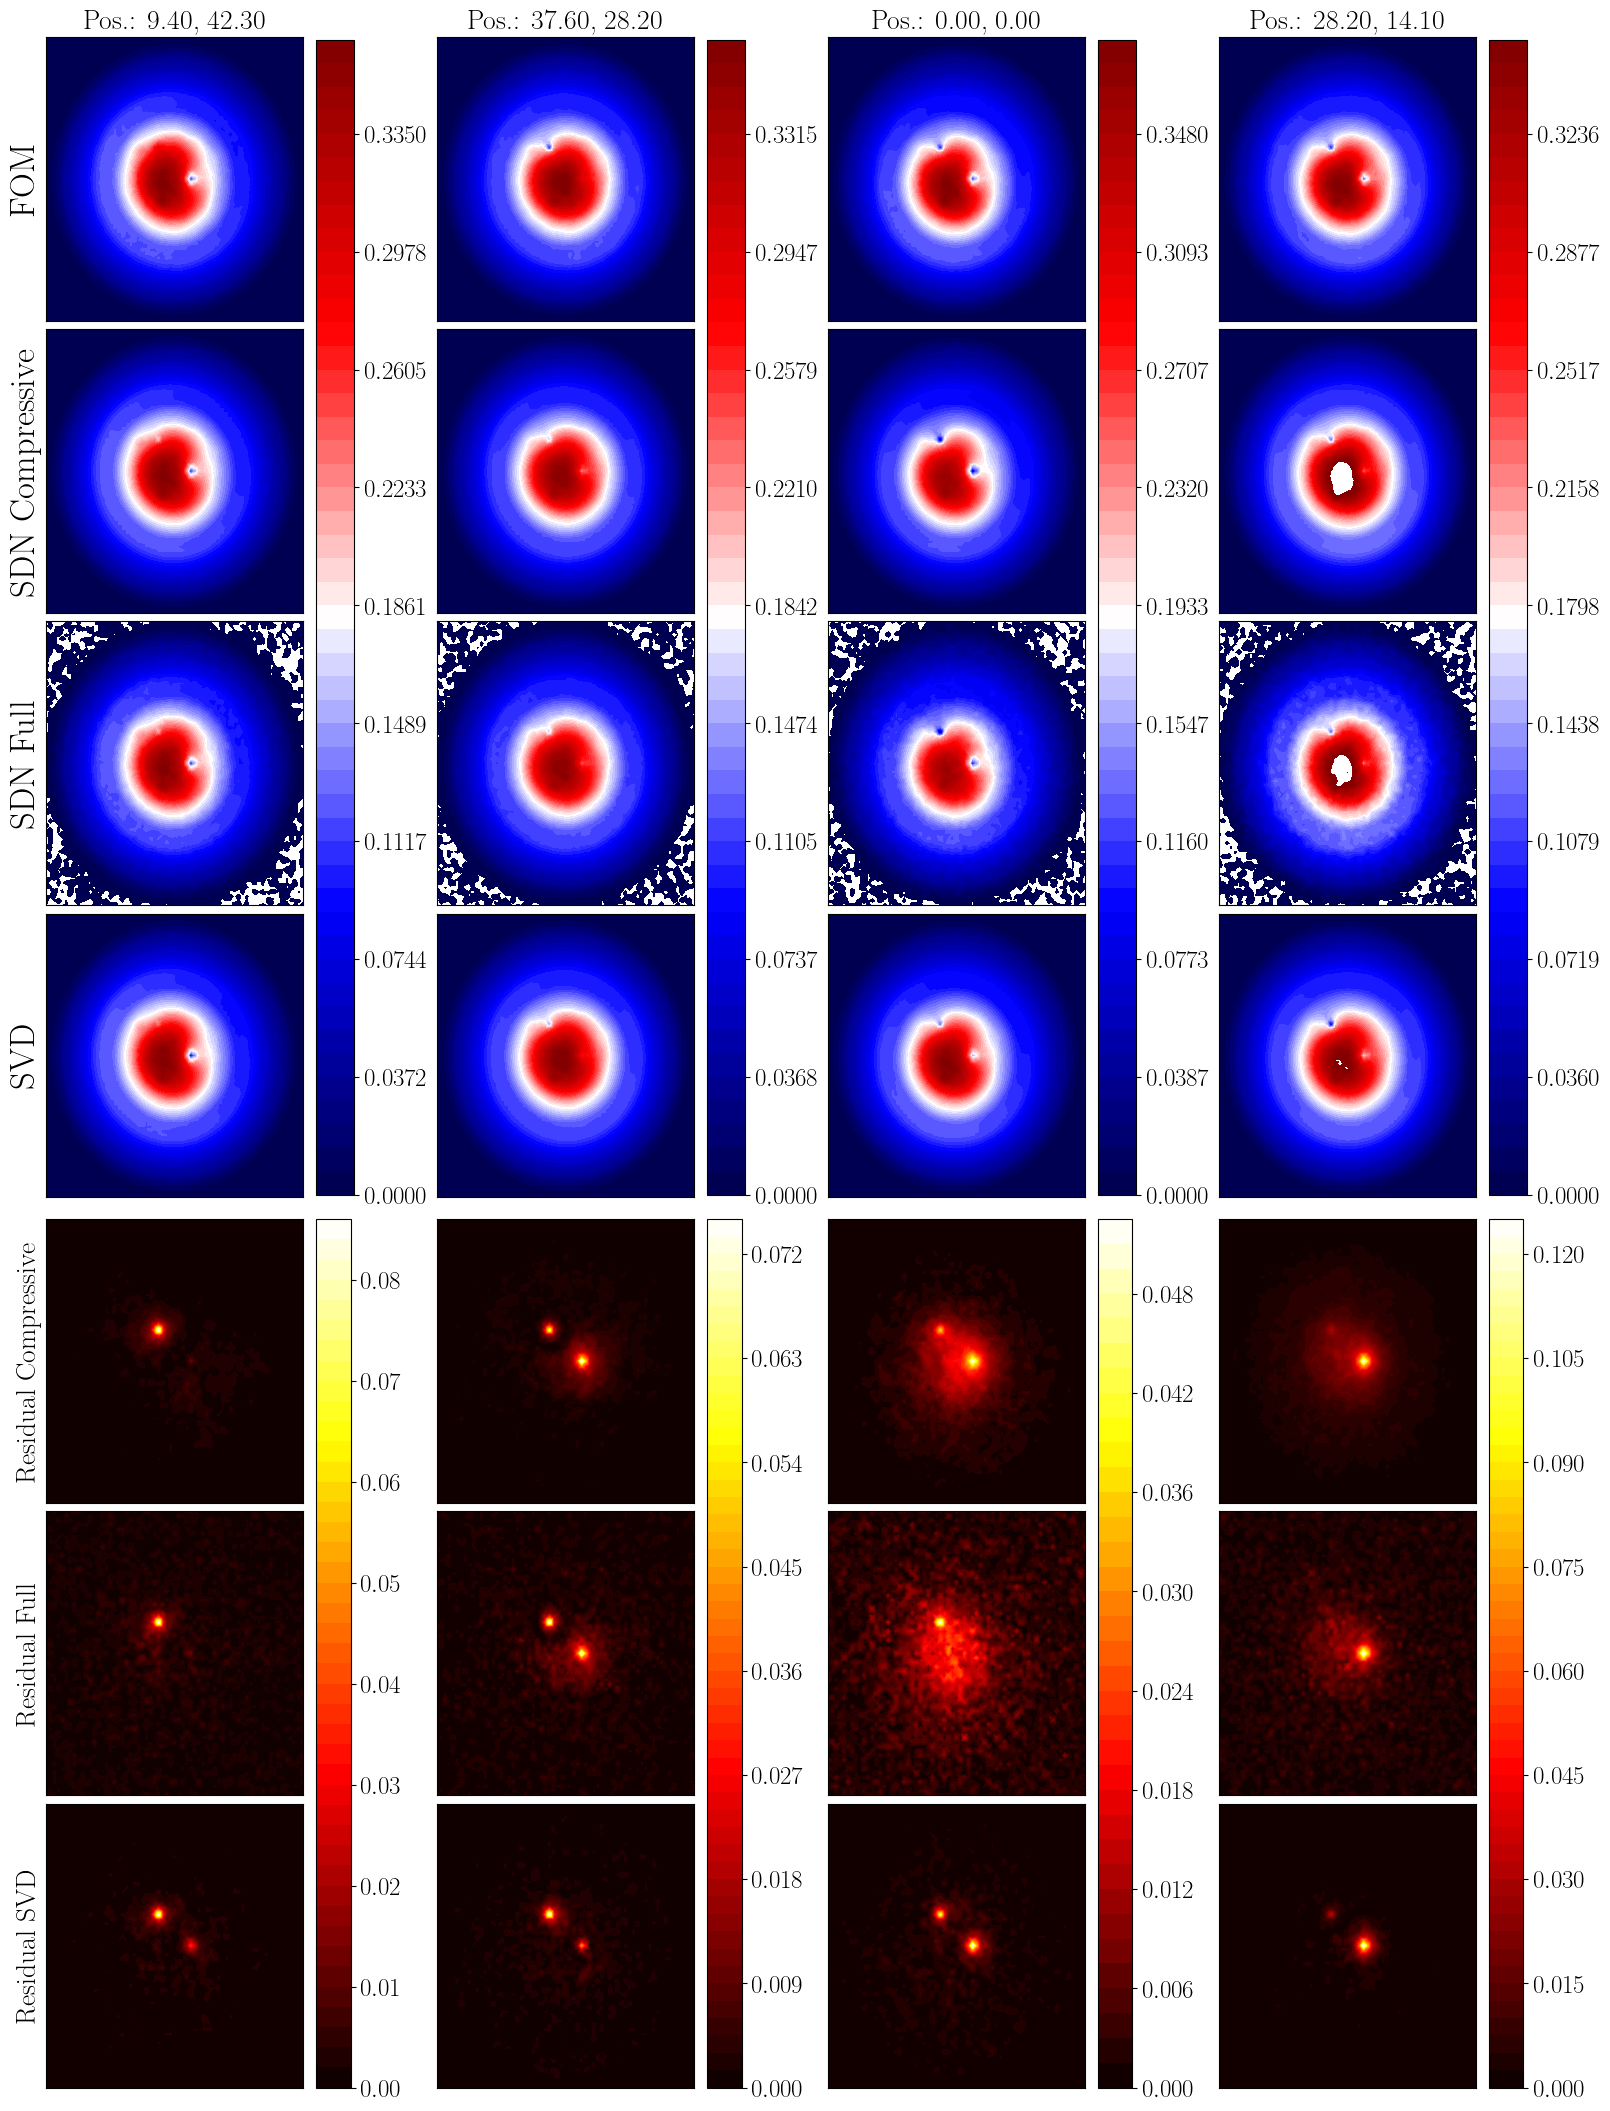

In [28]:
from utils.plots import PlotTriga
import pyvista as pv
from matplotlib import cm

pl = PlotTriga(pv.read(f'Data/mesh{_stats}.vtk'))

cmap = cm.seismic
cmap_res = cm.hot

nrows = 1 + (3 * 2) # 1 for FOM + 3 models and their residuals
ncols = 4

np.random.seed(42)
# test_params_to_plot = np.random.choice(len(test_params), size=ncols, replace=False)
test_params_to_plot = [7, 11, 8, 10] # 2 best, 2 worst

for normal in ['x', 'y', 'z']:

    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), constrained_layout=True)

    for ii, param_i in enumerate(test_params_to_plot):
        fom = test_data[:, param_i]
        model_compr = pred_sdn_compr[:, param_i]
        model_full  = pred_sdn_full[:, param_i]
        model_svd   = pred_svd_full[:, param_i]

        residual_compr = np.abs(fom - model_compr)
        residual_full  = np.abs(fom - model_full)
        residual_svd   = np.abs(fom - model_svd)

        _slice_fom = pl.get_slice(fom, name='fom', plane_normal=normal)[1]

        levels = np.linspace(0.0, np.max(_slice_fom), 50)
        cont = pl.plot_slice(axs[0, ii], fom,  normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[1, ii], model_compr, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[2, ii], model_full,  normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[3, ii], model_svd,   normal=normal, levels=levels, cmap=cmap)

        res_levels = np.linspace(0, max(np.max(residual_compr), np.max(residual_full), np.max(residual_svd)), len(levels))
        res_cont = pl.plot_slice(axs[4, ii], residual_compr, normal=normal, levels=len(levels), cmap=cmap_res)
        pl.plot_slice(axs[5, ii], residual_full, normal=normal, levels=len(levels), cmap=cmap_res)
        pl.plot_slice(axs[6, ii], residual_svd, normal=normal, levels=len(levels), cmap=cmap_res)

        cbar = fig.colorbar(cont, ax=axs[:4,ii], orientation='vertical', aspect=30)
        cbar.ax.tick_params(labelsize=18)

        cbar_res = fig.colorbar(res_cont, ax=axs[4:,ii], orientation='vertical', aspect=25)
        cbar_res.ax.tick_params(labelsize=18)

        # Set titles 
        axs[0, ii].set_title('Pos.: {:.2f}, {:.2f}'.format(*test_params[param_i]), fontsize=20)

    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
        
    axs[0, 0].set_ylabel('FOM', fontsize=25)
    axs[1, 0].set_ylabel('SDN Compressive', fontsize=25)
    axs[2, 0].set_ylabel('SDN Full', fontsize=25)
    axs[3, 0].set_ylabel('SVD', fontsize=25)
    axs[4, 0].set_ylabel('Residual Compressive', fontsize=20)
    axs[5, 0].set_ylabel('Residual Full', fontsize=20)
    axs[6, 0].set_ylabel('Residual SVD', fontsize=20)

    # fig.suptitle(f'SDN Reconstruction - {normal.upper()} plane', fontsize=35, y=0.95, 
    #              bbox=dict(facecolor='wheat', edgecolor='black', boxstyle='round,pad=0.5'))

    fig.savefig(os.path.join(path_res, f'sdn_reconstruction_{normal}_plane.png'), dpi=200, bbox_inches ='tight')
    # plt.close(fig)